In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os
import warnings
warnings.filterwarnings('ignore')

try:
    pd.options.future.infer_string = False
except Exception:
    pass

try:
    font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
    fm.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = 'Cambria'
except Exception:
    plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size'] = 11

import platform
if platform.system() == 'Windows':
    base = r"C:\\Users\\sosoq\\Documents\\GitHub\\EdenCampus-PhD\\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

# ── LOAD INPUTS FROM COMMITTED DATA (single source of truth) ──
from data_prep import load_inputs
_inputs = load_inputs(base, representative_weeks=True)
time_index     = _inputs["time_index"]
elec_demand    = _inputs["elec_demand"]
thermal_demand = _inputs["thermal_demand"]
pv_profile     = _inputs["pv_profile"]

# Grid capacity/demand charge (£/kW/yr). 0 disables. See capacity_charge.py.
GRID_CAPACITY_CHARGE = 120.0
print("Scenario comparison inputs loaded from committed data.")


Eden Campus inputs loaded from committed data files
  Snapshots:            672 h (representative weeks)
  Elec demand peak:     680.7 kW
  Elec demand annual:   185.2 MWh (subset)
  Thermal demand peak:  754.5 kW (MODELLED)
  PV peak:              80.5 % of 1000 kW
  PV annual (1 MW):     87.4 MWh
Scenario comparison inputs loaded from committed data.


In [2]:
def build_and_run_scenario(name, use_bess=False, use_pcm=False,
                            use_h2=False, use_heatpump=False):
    n = pypsa.Network()
    n.set_snapshots(time_index)

    # ── Carriers ──
    n.add("Carrier", "AC",       co2_emissions=0.233)
    n.add("Carrier", "hydrogen", co2_emissions=0.0)
    n.add("Carrier", "heat",     co2_emissions=0.0)

    # ── Buses ──
    n.add("Bus", "Electricity Bus", carrier="AC")
    if use_h2:
        n.add("Bus", "Hydrogen Bus", carrier="hydrogen")
    if use_pcm or use_heatpump:
        n.add("Bus", "Heat Bus", carrier="heat")

    # ── Solar PV ──
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", carrier="AC",
          p_nom=1000, p_max_pu=pv_profile,
          marginal_cost=0)

    # ── Grid ──
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", carrier="AC",
          p_nom=2000, marginal_cost=0.280)  # £/kWh
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", carrier="AC",
          p_nom=500, p_max_pu=0, p_min_pu=-1,
          marginal_cost=-0.050)  # £/kWh

    # ── BESS ──
    if use_bess:
        n.add("StorageUnit", "BESS",
              bus="Electricity Bus", carrier="AC",
              p_nom=500, max_hours=4,
              efficiency_store=0.95, efficiency_dispatch=0.95,
              standing_loss=0.0002, cyclic_state_of_charge=True)

    # ── Hydrogen LDES ──
    if use_h2:
        n.add("Link", "Electrolyser",
              bus0="Electricity Bus", bus1="Hydrogen Bus",
              p_nom=200, efficiency=0.70, marginal_cost=0.001)  # £/kWh
        n.add("Link", "Fuel Cell",
              bus0="Hydrogen Bus", bus1="Electricity Bus",
              p_nom=100, efficiency=0.50, marginal_cost=0.002)  # £/kWh
        n.add("Store", "Hydrogen Tank",
              bus="Hydrogen Bus", carrier="hydrogen",
              e_nom=5000, e_cyclic=True,
              standing_loss=0.0001)

    # ── Electrical Demand ──
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", carrier="AC",
          p_set=elec_demand)

    # ── Heat system ──
    if use_pcm or use_heatpump:
        n.add("Generator", "Backup Boiler",
              bus="Heat Bus", carrier="heat",
              p_nom=600, marginal_cost=0.110)  # £/kWh
        n.add("Load", "Thermal Demand",
              bus="Heat Bus", carrier="heat",
              p_set=thermal_demand)
        if use_heatpump:
            n.add("Link", "Heat Pump",
                  bus0="Electricity Bus", bus1="Heat Bus",
                  p_nom=300, efficiency=3.0, marginal_cost=0.0005)  # £/kWh
        if use_pcm:
            n.add("StorageUnit", "PCM TES",
                  bus="Heat Bus", carrier="heat",
                  p_nom=200, max_hours=8,
                  efficiency_store=0.95, efficiency_dispatch=0.92,
                  standing_loss=0.001, cyclic_state_of_charge=True)

    # ── Solve ──
    from capacity_charge import add_capacity_charge
    n.optimize.create_model()
    add_capacity_charge(n, GRID_CAPACITY_CHARGE, import_generator="Grid Import")
    n.optimize.solve_model(solver_name='highs')

    # ── Extract KPIs ──
    pv_gen        = n.generators_t.p["Solar PV"]
    grid_import   = n.generators_t.p["Grid Import"]
    grid_export   = n.generators_t.p["Grid Export"].abs()
    total_pv      = pv_gen.sum()
    total_demand  = elec_demand.sum()
    total_import  = grid_import.sum()
    total_export  = grid_export.sum()
    pv_consumed   = total_pv - total_export
    self_consump  = (pv_consumed / total_pv * 100) if total_pv > 0 else 0
    solar_frac    = (pv_consumed / total_demand * 100) if total_demand > 0 else 0
    peak_baseline = elec_demand.max()
    peak_with     = grid_import.max()
    peak_red      = ((peak_baseline - peak_with) / peak_baseline * 100)
    co2_saved     = (pv_consumed * 0.233) / 1000
    total_cost    = n.objective

    return {
        'Scenario':               name,
        'PV Generation (MWh)':    round(total_pv    / 1000, 1),
        'Grid Import (MWh)':      round(total_import / 1000, 1),
        'Grid Export (MWh)':      round(total_export / 1000, 1),
        'Self-Consumption (%)':   round(self_consump, 1),
        'Solar Fraction (%)':     round(solar_frac,   1),
        'Peak Reduction (%)':     round(peak_red,     1),
        'CO2 Saved (tonnes)':     round(co2_saved,    1),
        'Total Cost (£k)':        round(total_cost / 1000, 1),
    }

print("Running all 5 scenarios — please wait...")
print("=" * 55)

scenarios_config = [
    ("S0: PV Only",          False, False, False, False),
    ("S1: PV + BESS",        True,  False, False, False),
    ("S2: PV + PCM TES",     False, True,  False, True),
    ("S3: PV + H2 LDES",     False, False, True,  False),
    ("S4: Full Hybrid",      True,  True,  True,  True),
]

results = []
for name, bess, pcm, h2, hp in scenarios_config:
    print(f"  Running {name}...")
    r = build_and_run_scenario(name, bess, pcm, h2, hp)
    results.append(r)
    print(f"    Cost: £{r['Total Cost (£k)']:.0f}k  |  "
          f"Solar: {r['Solar Fraction (%)']:.1f}%  |  "
          f"CO2: {r['CO2 Saved (tonnes)']:.1f}t")

results_df = pd.DataFrame(results).set_index('Scenario')
print("\n" + "=" * 55)
print("ALL SCENARIOS COMPLETE")
print("=" * 55)
print(results_df.to_string())

Running all 5 scenarios — please wait...
  Running S0: PV Only...


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.1s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 2017 primals, 5376 duals
Objective: 1.13e+05
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The variable 'peak_import' could not be mapped to the network component because it does not include the symbol '-'.


...


INFO:linopy.io: Writing time: 0.08s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 10081 primals, 23520 duals
Objective: 8.79e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The variable 'peak_import' could not be mapped to the network component because it does not include the symbol '-'.


INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance, peak_import_def were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-bytr_19z has 23520 rows; 10081 cols; 37632 nonzeros
Coefficient ranges:
  Matrix  [5e-01, 3e+00]
  Cost    [5e-04, 1e+02]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 5e+03]
Presolving model
4704 rows, 9688 cols, 18423 nonzeros  0s
Dependent equations search running on 3332 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
4004 rows, 8988 cols, 17023 nonzeros  0s
Presolve reductions: rows 4004(-19516); columns 8988(-1093); nonzeros 17023(-20609) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       5284     8.7921046311e+04 Pr: 0(0) 0.1s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-bytr_19z
Model status        : Optimal
Simplex   itera

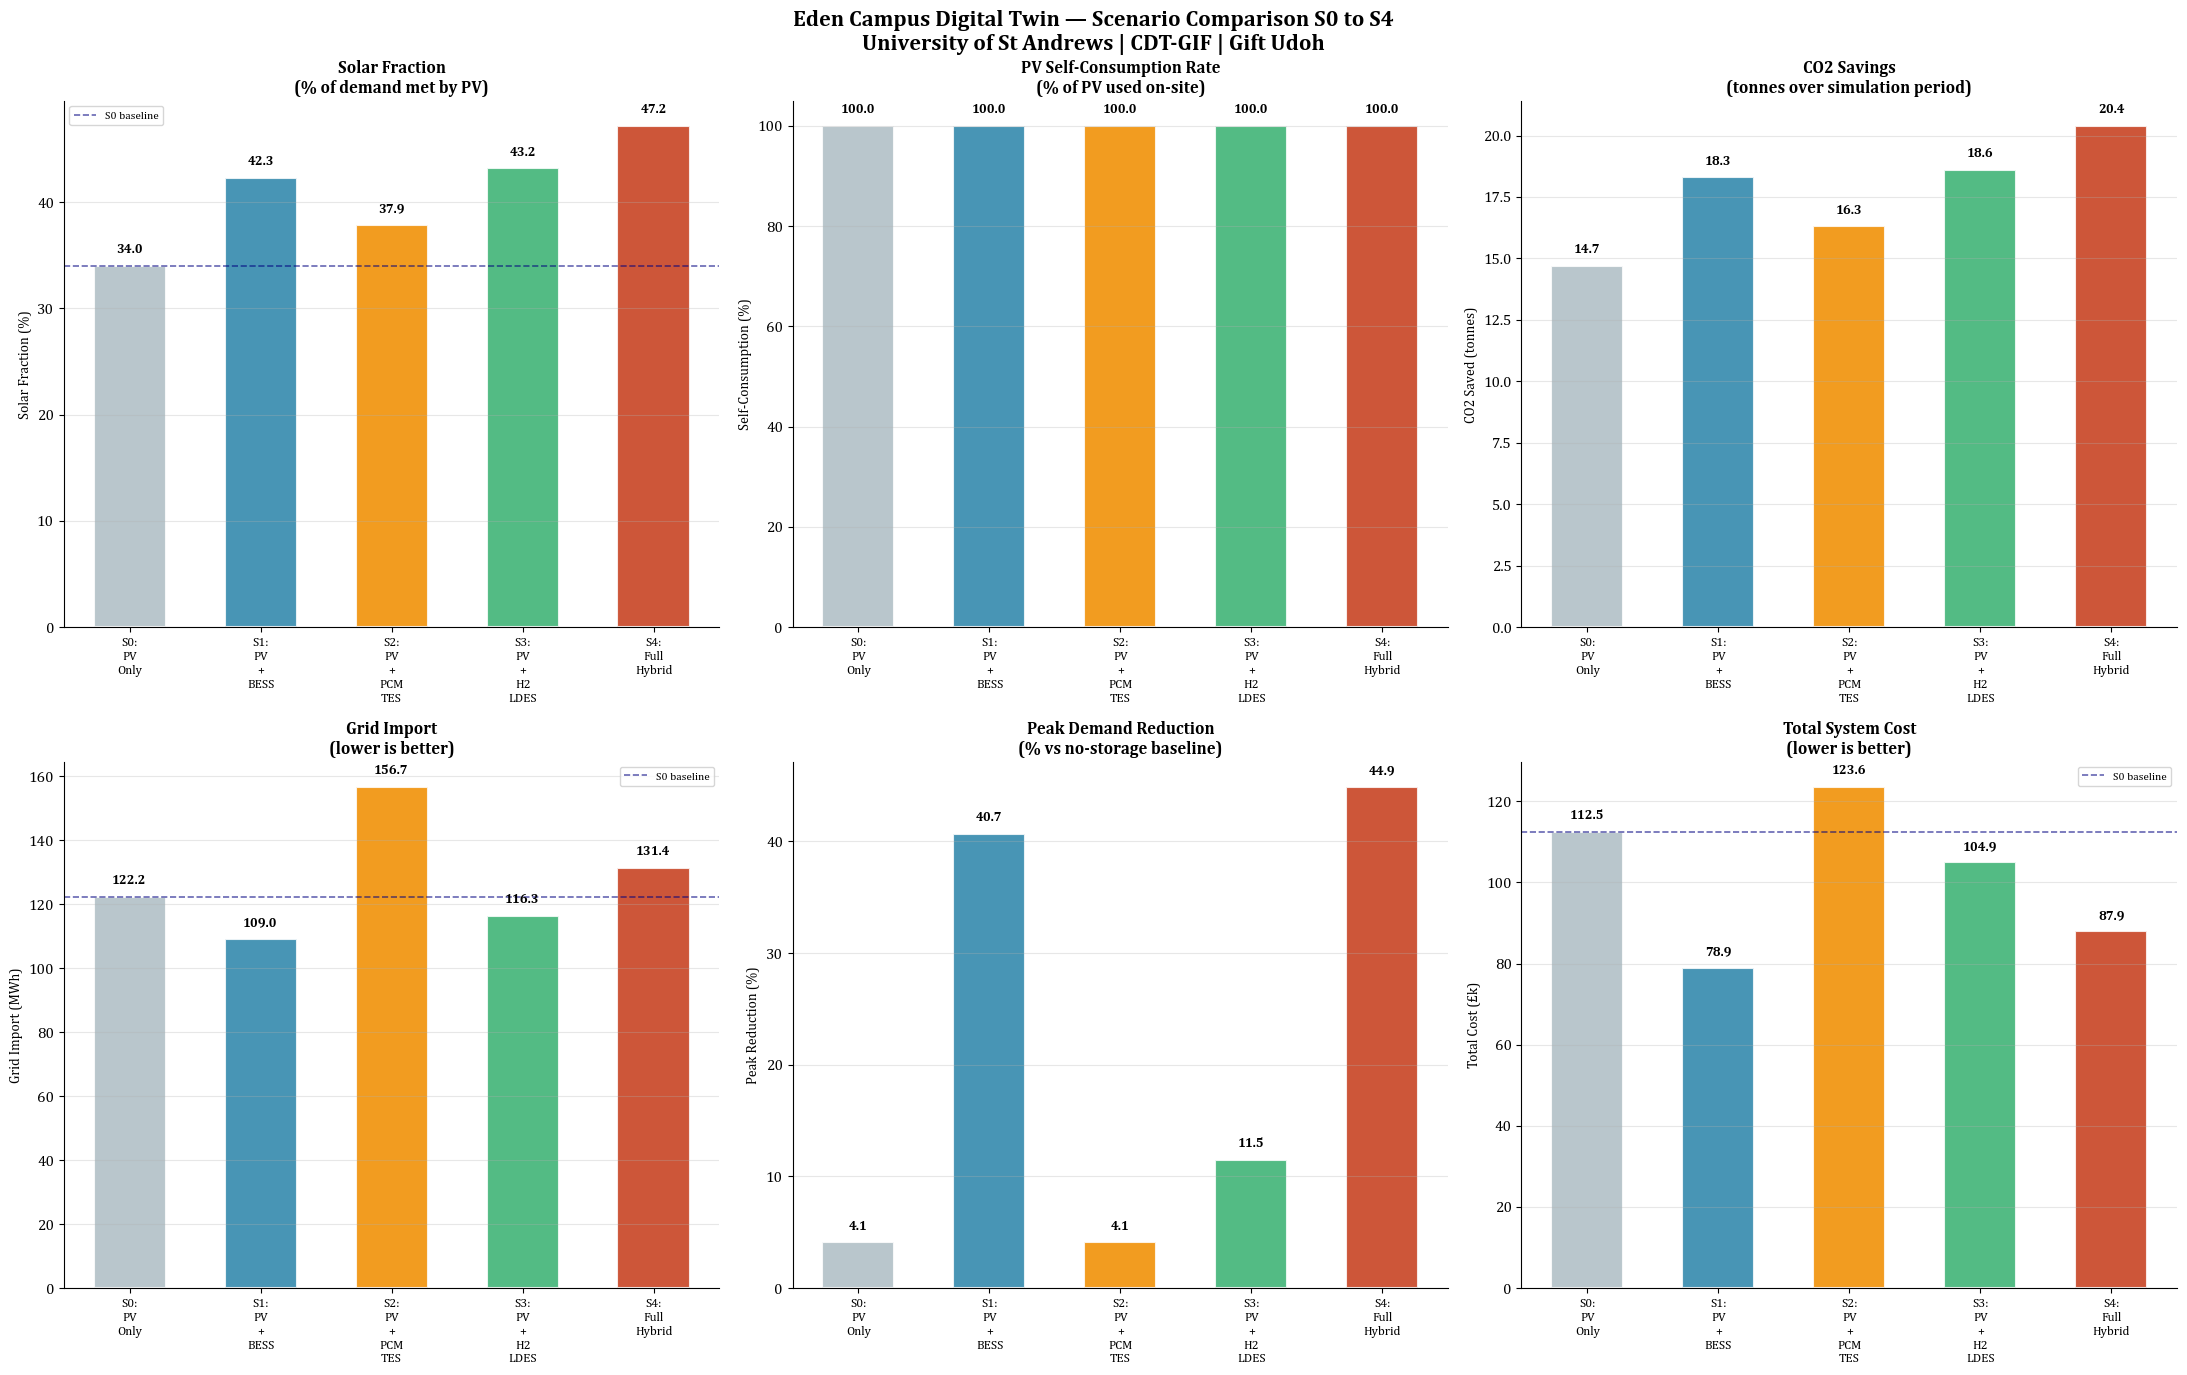

Scenario comparison chart saved!


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
fig.suptitle(
    'Eden Campus Digital Twin — Scenario Comparison S0 to S4\n'
    'University of St Andrews | CDT-GIF | Gift Udoh',
    fontsize=16, fontweight='bold')

scenarios  = results_df.index.tolist()
bar_colors = ['#B0BEC5', '#2E86AB', '#F18F01', '#3BB273', '#C73E1D']
x          = np.arange(len(scenarios))
width      = 0.55

def bar_chart(ax, metric, title, ylabel, color_list, annotate=True):
    values = results_df[metric].values
    bars   = ax.bar(x, values, width, color=color_list,
                    edgecolor='white', linewidth=1.5, alpha=0.88)
    if annotate:
        for bar, val in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + abs(max(values)) * 0.02,
                    f'{val:.1f}', ha='center', va='bottom',
                    fontsize=9.5, fontweight='bold')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xticks(x)
    ax.set_xticklabels([s.replace(' ', '\n') for s in scenarios],
                        fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

bar_chart(axes[0, 0], 'Solar Fraction (%)',
          'Solar Fraction\n(% of demand met by PV)',
          'Solar Fraction (%)', bar_colors)

bar_chart(axes[0, 1], 'Self-Consumption (%)',
          'PV Self-Consumption Rate\n(% of PV used on-site)',
          'Self-Consumption (%)', bar_colors)

bar_chart(axes[0, 2], 'CO2 Saved (tonnes)',
          'CO2 Savings\n(tonnes over simulation period)',
          'CO2 Saved (tonnes)', bar_colors)

bar_chart(axes[1, 0], 'Grid Import (MWh)',
          'Grid Import\n(lower is better)',
          'Grid Import (MWh)', bar_colors)

bar_chart(axes[1, 1], 'Peak Reduction (%)',
          'Peak Demand Reduction\n(% vs no-storage baseline)',
          'Peak Reduction (%)', bar_colors)

bar_chart(axes[1, 2], 'Total Cost (£k)',
          'Total System Cost\n(lower is better)',
          'Total Cost (£k)', bar_colors)

# ── Add S0 baseline reference line on relevant charts ──
s0_solar  = results_df.loc['S0: PV Only', 'Solar Fraction (%)']
s0_cost   = results_df.loc['S0: PV Only', 'Total Cost (£k)']
s0_import = results_df.loc['S0: PV Only', 'Grid Import (MWh)']

for ax, val in [
    (axes[0, 0], s0_solar),
    (axes[1, 0], s0_import),
    (axes[1, 2], s0_cost),
]:
    ax.axhline(val, color='navy', linewidth=1.2,
               linestyle='--', alpha=0.6, label='S0 baseline')
    ax.legend(fontsize=8)

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "scenario_comparison_S0_S4.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print("Scenario comparison chart saved!")

In [4]:
import openpyxl

# ── Save as Excel ──
excel_path = os.path.join(base, "04_results/tables",
                           "scenario_comparison_S0_S4.xlsx")
os.makedirs(os.path.join(base, "04_results/tables"), exist_ok=True)
results_df.to_excel(excel_path)
print(f"Excel table saved: {excel_path}")

# ── Print LaTeX table for thesis ──
print("\n── LaTeX Table (copy into thesis) ──\n")
print(results_df.to_latex(
    caption='Scenario comparison KPIs for Eden Campus digital twin.',
    label='tab:scenario_comparison',
    float_format='{:.1f}'.format))

# ── Print summary of best scenario per KPI ──
print("\n── Best Scenario per KPI ──")
for col in results_df.columns:
    if 'Cost' in col or 'Import' in col:
        best = results_df[col].idxmin()
        val  = results_df[col].min()
    else:
        best = results_df[col].idxmax()
        val  = results_df[col].max()
    print(f"  {col:<30} → {best}  ({val:.1f})")

Excel table saved: /Users/everythingkrypto/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD/04_results/tables/scenario_comparison_S0_S4.xlsx

── LaTeX Table (copy into thesis) ──

\begin{table}
\caption{Scenario comparison KPIs for Eden Campus digital twin.}
\label{tab:scenario_comparison}
\begin{tabular}{lrrrrrrrr}
\toprule
 & PV Generation (MWh) & Grid Import (MWh) & Grid Export (MWh) & Self-Consumption (%) & Solar Fraction (%) & Peak Reduction (%) & CO2 Saved (tonnes) & Total Cost (£k) \\
Scenario &  &  &  &  &  &  &  &  \\
\midrule
S0: PV Only & 63.0 & 122.2 & 0.0 & 100.0 & 34.0 & 4.1 & 14.7 & 112.5 \\
S1: PV + BESS & 78.3 & 109.0 & 0.0 & 100.0 & 42.3 & 40.7 & 18.3 & 78.9 \\
S2: PV + PCM TES & 70.1 & 156.7 & 0.0 & 100.0 & 37.9 & 4.1 & 16.3 & 123.6 \\
S3: PV + H2 LDES & 80.0 & 116.3 & 0.0 & 100.0 & 43.2 & 11.5 & 18.6 & 104.9 \\
S4: Full Hybrid & 87.4 & 131.4 & 0.0 & 100.0 & 47.2 & 44.9 & 20.4 & 87.9 \\
\bottomrule
\end{tabular}
\end{table}


── Best Scenario per KPI ──
  PV Generation